# 시범 구간 · Chatbot에서 Agent로

**1일차 Agent 사고방식 블록의 30~90분 / 60분**

이 노트북은 최종 교안의 **한 구간이 어떻게 보일지** 확인하기 위한 시범본입니다. 그림을 보고 질문한 다음, 작은 코드를 실행하고, CodeMate에 개선을 맡겨 결과를 검토합니다.

오늘의 질문: **LLM은 날씨를 직접 조회하는가, 아니면 조회할 도구를 제안하는가?**

실행 조건: Python만 필요합니다. 실제 LLM API·날씨 서비스·자격증명은 사용하지 않습니다.


## 30~35분 · 먼저 그림을 보고 예상하기

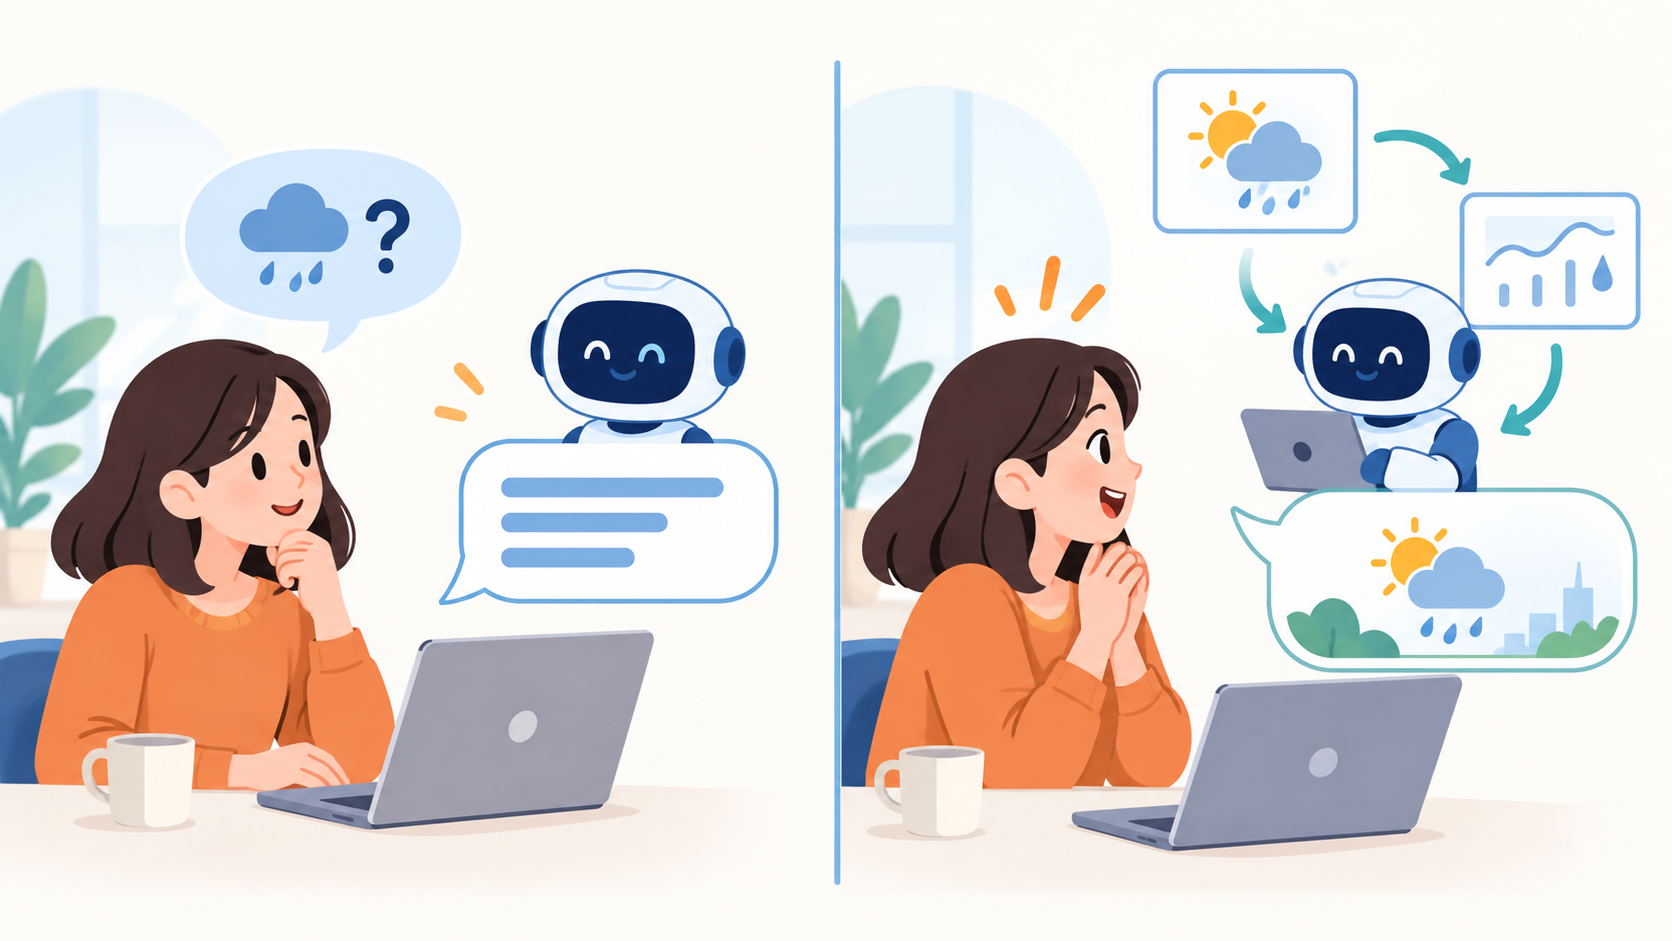

왼쪽과 오른쪽에서 **추가된 행동**은 무엇인가요? 오른쪽의 답을 믿으려면 어떤 결과를 확인해야 할까요?


## 35~50분 · 도구 호출은 제안과 실행으로 나뉩니다

기본 Chatbot은 입력 문맥을 바탕으로 답변 텍스트를 만듭니다. 도구를 쓰는 Agent는 필요할 때 `도구 이름`과 `인자`를 구조화해 **제안**할 수 있습니다. 그러나 모델이 Python 함수를 직접 실행하는 것은 아닙니다. 우리 프로그램이 그 제안을 검사하고, 허용된 도구만 실행하며, 결과를 다시 전달합니다.

아래 코드의 `request`는 **모델이 제안했다고 가정한 데이터**입니다. 실제 모델 호출이 없다는 점을 먼저 확인하세요. 원본 교안 `1-1` 16~19쪽의 `get_weather` 설명을 실행 가능한 최소 예제로 바꿨습니다.


In [ ]:
def get_weather(location: str) -> str:
    # 수업용 고정 데이터: 실제 날씨 API가 아닙니다.
    weather = {"Seoul": "맑음", "Dongtan": "흐림"}
    return weather.get(location, "확인 가능한 날씨 데이터 없음")


def run_tool(request: dict) -> str:
    allowed_tools = {"get_weather": get_weather}
    name = request.get("tool")
    arguments = request.get("arguments")
    if name not in allowed_tools:
        raise ValueError(f"허용되지 않은 도구: {name}")
    if not isinstance(arguments, dict) or set(arguments) != {"location"}:
        raise ValueError("location 인자 하나가 필요합니다")
    if not isinstance(arguments["location"], str) or not arguments["location"].strip():
        raise ValueError("location은 빈 문자열이 아닌 글자여야 합니다")
    return allowed_tools[name](arguments["location"])


request = {"tool": "get_weather", "arguments": {"location": "Dongtan"}}
observation = run_tool(request)
print("도구 실행 결과:", observation)


## 50~55분 · 실행 직후 확인

1. `request`를 만든 주체는 이 예제에서 누구인가요? 실제 LLM을 호출했나요?
2. `tool`을 `send_email`로 바꾸면 왜 실행되지 않나요?
3. `location`이 비어 있으면 어떤 오류가 나나요?

도구 제안과 실제 실행의 책임이 다른 것을 확인한 뒤 다음 흐름으로 넘어갑니다.


## 55~65분 · 한 번의 도구 호출을 반복 흐름으로 확장하기

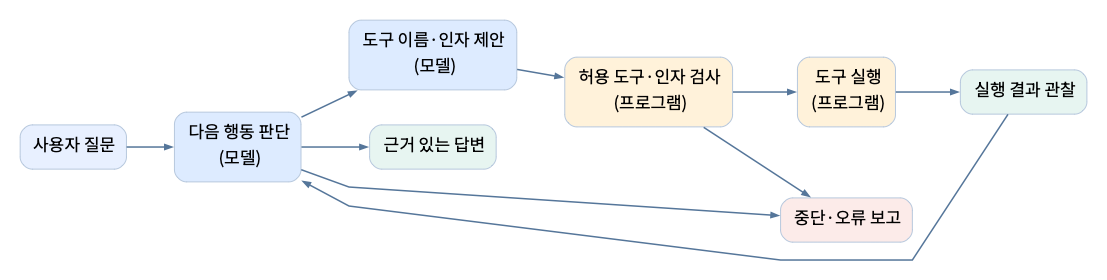

**판단(Reason) → 실행(Action) → 관찰(Observation)**을 목표를 달성할 때까지 반복할 수 있습니다. 중요한 것은 도구 실행 전 검사와 **끝낼 조건**입니다. 원본 교안 `1-1` 20~22쪽의 Agent 개념을 코드 실행 순서에 맞춰 다시 그렸습니다.


In [ ]:
def decide(question: str, observations: list[str]) -> tuple[str, object]:
    # 실제 LLM 대신 흐름을 보여 주는 결정적 예제입니다.
    if observations:
        return "answer", f"도구에서 확인한 내용: {observations[-1]}"
    if "동탄" in question:
        return "tool", {"tool": "get_weather", "arguments": {"location": "Dongtan"}}
    return "answer", "이 예제로는 확인할 수 없습니다."


question = "동탄 날씨는 어때?"
observations: list[str] = []
max_steps = 3
for step in range(1, max_steps + 1):
    action, payload = decide(question, observations)
    print(f"{step}회 판단:", action)
    if action == "answer":
        print(payload)
        break
    observations.append(run_tool(payload))
    print("관찰:", observations[-1])
else:
    raise RuntimeError("최대 반복 횟수 안에 답을 만들지 못했습니다")


## 65~85분 · CodeMate와 개선하기

CodeMate에 다음을 지시하세요.

> 현재 `decide()`와 반복문을 읽고 먼저 실행 흐름을 설명해 주세요. `question`, `observations`, `max_steps`를 받는 함수로 정리하되, 허용되지 않은 도구는 실행하지 말고, 근거를 얻지 못한 경우 답을 꾸미지 않게 해 주세요. 종료 조건과 오류가 나는 입력 두 가지를 먼저 제시한 뒤 코드를 작성해 주세요.

생성된 코드를 아래 셀에서 실행해 보세요. 원본 예제와 결과가 어떻게 달라졌는지 확인합니다.


In [ ]:
# CodeMate가 만든 함수를 여기에 넣고 실행합니다.
# 연습 전에는 이 셀이 아무 작업도 하지 않습니다.


## 85~90분 · 결과 검토와 다음 연결

- 도구 이름과 인자를 **실행 전에** 검사하나요?
- 답변에 없는 근거를 덧붙이지 않나요?
- 목표를 달성했거나 최대 횟수에 도달했을 때 멈추나요?
- 수강생이 `Dongtan` 대신 다른 값을 넣었을 때 무엇이 달라지나요?

**시간 내 최소 결과물:** 도구 제안·실행·관찰·종료 지점을 코드에서 찾아 설명합니다.

**빠른 수강생의 확장 과제:** 같은 함수를 두 번째 도구로 확장하되, 도구 선택이 실패한 사례도 보여 줍니다.

**원본:** `docs/raw/Chapter01/day01/1-1-ai-agent-design-thinking.pdf` 15~22쪽 · `docs/notebooks/Chapter01/day01/1-1-ai-agent-design-thinking.ipynb` · 이후 실습 `src/raw/Chapter01/02-langchain/02_tool_calling.py`
